In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn # for CNN layer and loss function
import matplotlib.pyplot as plt
import numpy as np
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [ ]:
import kagglehub
path = kagglehub.dataset_download("kaustubhb999/tomatoleaf")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'tomatoleaf' dataset.
Path to dataset files: /kaggle/input/tomatoleaf


In [ ]:
import torchvision.transforms as transforms
size = 128
train_transform = transforms.Compose([      # it helps to combine multiple image processing in one pipeline instead of applying transformation separately.
    transforms.Resize((size, size)),        # resize the images to model input size, so the dymention is now 128*128 for all images.
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation to increase the varieties of possible images.
    transforms.RandomRotation(15),        # rotate ±15 degrees to increase the varieties of possible images.
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → tensor [0,1]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),  # resize the images to model input size, so the dymention is now 128*128 for all images.
    transforms.ToTensor(),
])



In [ ]:
train_folder = '/kaggle/input/tomatoleaf/tomato/train' # checked manually.
test_folder = '/kaggle/input/tomatoleaf/tomato/val'   # checked manually.

train_data = datasets.ImageFolder(train_folder,transform = train_transform) # loads images from the folder and folder er nam wise label kore. Training set er upor training transformation apply.
test_data = datasets.ImageFolder(test_folder,transform = val_transform)

print("Number of classes:", len(train_data.classes))
print("Training images:", len(train_data))
print("Validation images:", len(test_data))

Number of classes: 10
Training images: 10000
Validation images: 1000


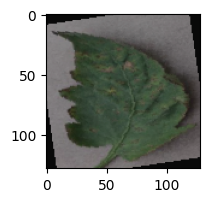

In [ ]:
plt.figure(figsize = (2,2)) # 2x2 inch er image.
plt.imshow(train_data[800][0].permute(1,2,0)) # img at train_data[800][0]. label will be train_data[800][0]. permute to change the dymention. 0 = channel, 1 = height, 2 = weight.

In [ ]:
#important HyperParameters
batch_size = 32 # number of images per batch. for training 10000/32 = 312.5
learning_rate=0.001
minimum_learning_rate=1e-4
epochs = 30 # total training rounds

In [ ]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,num_workers=2, pin_memory=True) # DataLoader Loads images from kaggle to each batch.
val_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

In [ ]:
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        # Feature extraction layers
        self.features = nn.Sequential(    # nn.Sequential combines multiple layer in one layer.
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # 3 inputs connect to 32 outputs with a kernel size of 3 with stride 1.
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),  # ReLU apply. negative value to 0, positive value unchanged.
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # max pool in 2x2 kernel.
            nn.Dropout2d(0.1), # 10% features dropped to reduce overfitting.

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3)
        )

        # Classification layers
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(), # converts multi dymentional feature to one dimentional vector.
            nn.Linear(128 * 4 * 4, 256), # linear layer with 128*4*4 inputs and 256 outputs.
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 10) # 256 inputs connected to final 10 outputs or classes.
        )

    def forward(self, x): # receives the image
        x = self.features(x) # sends the image through feature extraction
        x = self.classifier(x) # sends the extracted feature through classification layer and gets the class
        return x # returns the final class scores

#1. Get the Model
model = CNNModel().to(device)
# 2. Define optimizer
optimizer = Adam(model.parameters(), lr=learning_rate) # updates model weights.
# 3. Define LR scheduler
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate) # gradually reducing the learning rate. Large updates early and small updates later.
# 4. Define loss function
criterion = nn.CrossEntropyLoss()

#from torchsummary import summary
#summary(model, input_size=(3,size,size));

In [ ]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train() # sets to training mode
    total_loss = 0 # total loss in all batch.
    correct = 0 # total correct prediction in all batch.
    total = 0   #total images.
    for images, labels in loader: # loads one batch at a time.

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images) # forward
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step() # updates the weights based on the calculated gradient
        optimizer.zero_grad() # gradient set to 0 again.

        total_loss += loss.item() # calculating total loss. .item() converts tensor value into a number.

        # compute accuracy
        _, preds = torch.max(outputs, 1) # finds maximum class score and saves the index. this is the maximum class index.
        correct += (preds == labels).sum().item() # calculating correct predictions.
        total += labels.size(0) # calculating total images by returning the labels in the current batch.

    train_loss = total_loss / len(loader) # total loss / number of batches performed.
    train_acc = correct / total   # total correct / total images.

    return train_loss, train_acc

def validate_epoch(model, loader, criterion, device):

    model.eval() # sets to validation mode

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad(): # No gradient. We will only check performance not update anything. No backward or optimizer.
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()  # calculating total loss. .item() converts tensor value into a number.

            _, preds = torch.max(outputs, 1) # finds maximum class score and saves the index. this is the maximum class index.
            correct += (preds == labels).sum().item() # calculating correct predictions.
            total += labels.size(0) # calculating total images by returning the size of labels in the current batch.

    val_loss = total_loss / len(loader) # total loss / number of batches performed.
    val_acc = correct / total # total correct / total images.

    return val_loss, val_acc

In [ ]:
train_losses = [] # training loss after each epoch
train_accuracies = [] # training accuracy after each epoch
val_losses = [] # validation loss after each epoch
val_accuracies = [] # validation accuracy after each epoch

for epoch in range(epochs):
    print(f"----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}") # getting the learning rate.

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device) #train_loss, train_acc after each epoch
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device) # val_loss, val_acc after each epoch.
    scheduler.step() # updating the learning rate.

    train_losses.append(train_loss) # appending the values.
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

----------------------------------------------------
Epoch 1/30, LR: 0.001
Train Loss: 1.2262 | Train Acc: 0.5700
Val Loss: 0.8529 | Val Acc: 0.6870
----------------------------------------------------
Epoch 2/30, LR: 0.000997535
Train Loss: 0.8375 | Train Acc: 0.7102
Val Loss: 0.7262 | Val Acc: 0.7550
----------------------------------------------------
Epoch 3/30, LR: 0.000990166
Train Loss: 0.7323 | Train Acc: 0.7461
Val Loss: 0.6509 | Val Acc: 0.7630
----------------------------------------------------
Epoch 4/30, LR: 0.000977975
Train Loss: 0.6599 | Train Acc: 0.7701
Val Loss: 0.7313 | Val Acc: 0.7480
----------------------------------------------------
Epoch 5/30, LR: 0.000961095
Train Loss: 0.6390 | Train Acc: 0.7825
Val Loss: 0.5512 | Val Acc: 0.8000
----------------------------------------------------
Epoch 6/30, LR: 0.000939711
Train Loss: 0.5767 | Train Acc: 0.7985
Val Loss: 0.7257 | Val Acc: 0.7390
----------------------------------------------------
Epoch 7/30, LR: 0.00091

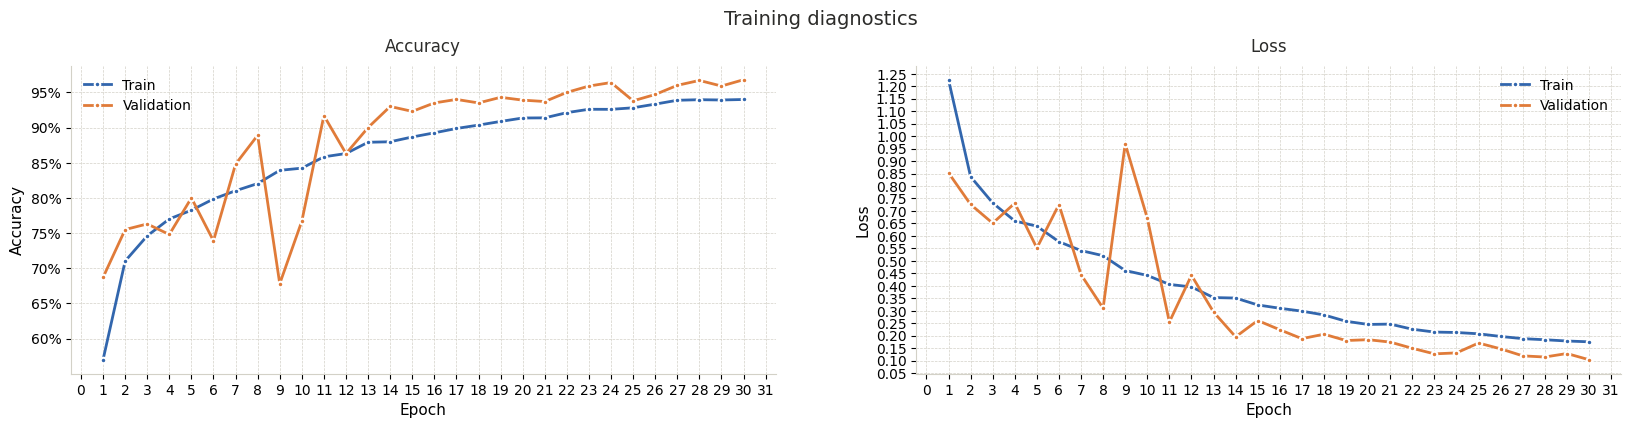

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker # axis markings
import matplotlib.gridspec as gridspec # arranges multigraph
import numpy as np

BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"
BLACK  = "#000000"

# changing default settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": BLACK,
    "ytick.color": BLACK,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs+1) # arranges a sequence of numbers from 1.
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2) # creates a layout with one row and two columns so graphs appear side by side.

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2,   label="Train",      marker="o", ms=4, mew=1.5, mec="white") # plotting training accuracy
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2,   label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-") # plotting validation accuracy
ax1.xaxis.set_major_locator(mticker.MultipleLocator(1)) # controls axis spacing
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%")) # formats axis values
ax1.set_xlabel("Epoch", color=BLACK, fontsize=11) # x label
ax1.set_ylabel("Accuracy", color=BLACK, fontsize=11) # y label
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10) # title
ax1.legend(frameon=False, fontsize=10, labelcolor=BLACK) # legend

# ── Loss ──────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")  # plotting training loss
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-") # plotting validation accuracy loss
ax2.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax2.set_xlabel("Epoch", color=BLACK, fontsize=11)
ax2.set_ylabel("Loss",  color=BLACK, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=BLACK)

fig.suptitle("Training diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150) # saves pdf as pdf.
plt.show()

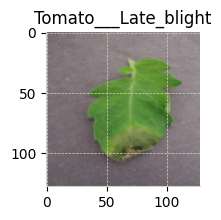

In [ ]:
model.eval()
with torch.no_grad(): # disables gradient calculations.
  ix = torch.randint(0,len(test_data),()) # generates a random value from  0 to len(test_data).
  img = test_data[ix][0].unsqueeze(0).to(device) # getting image from the index value. unsqueeze(0) adds a new dimention at 0 position as CNN expects a batch of images.
  np_output = model(img).cpu().detach().numpy() # detach() separates temsor from the computational graph and numpy() convert tensor to array.
  pred = np.exp(np_output)/np.sum(np.exp(np_output)) # softmax implementaion.
  plt.figure(figsize=(2,2))
  plt.imshow(img.squeeze(0).permute(1,2,0).cpu().detach().numpy())
  plt.title(train_data.classes[pred[0].argmax()])     # .argmax() returns the highest probability. and getting the class name.
  plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

class_names = test_data.classes  # from ImageFolder

model.eval()
misclassified = [] # stores incorrect predicted images.
all_preds = [] # stores all predicted labels
all_labels = [] # stores all actual labels

with torch.no_grad():
    for images, labels in val_loader: # loads validation images
        images, labels = images.to(device), labels.to(device) # stores images and labels.
        outputs = model(images)  # passing img through cnn
        _, preds = torch.max(outputs, 1) # storing the highest class score index.

        # Save all predictions and labels for confusion matrix
        all_preds.extend(preds.cpu().numpy()) # add the predicted labels to the list
        all_labels.extend(labels.cpu().numpy()) # add the actual labels to the list

        # Store misclassified images
        for img, true, pred in zip(images, labels, preds):
            if true != pred: # if not matches
                misclassified.append((img.cpu(), true.cpu(), pred.cpu())) # stores images, actual label and predicted label.

Total misclassified samples: 32


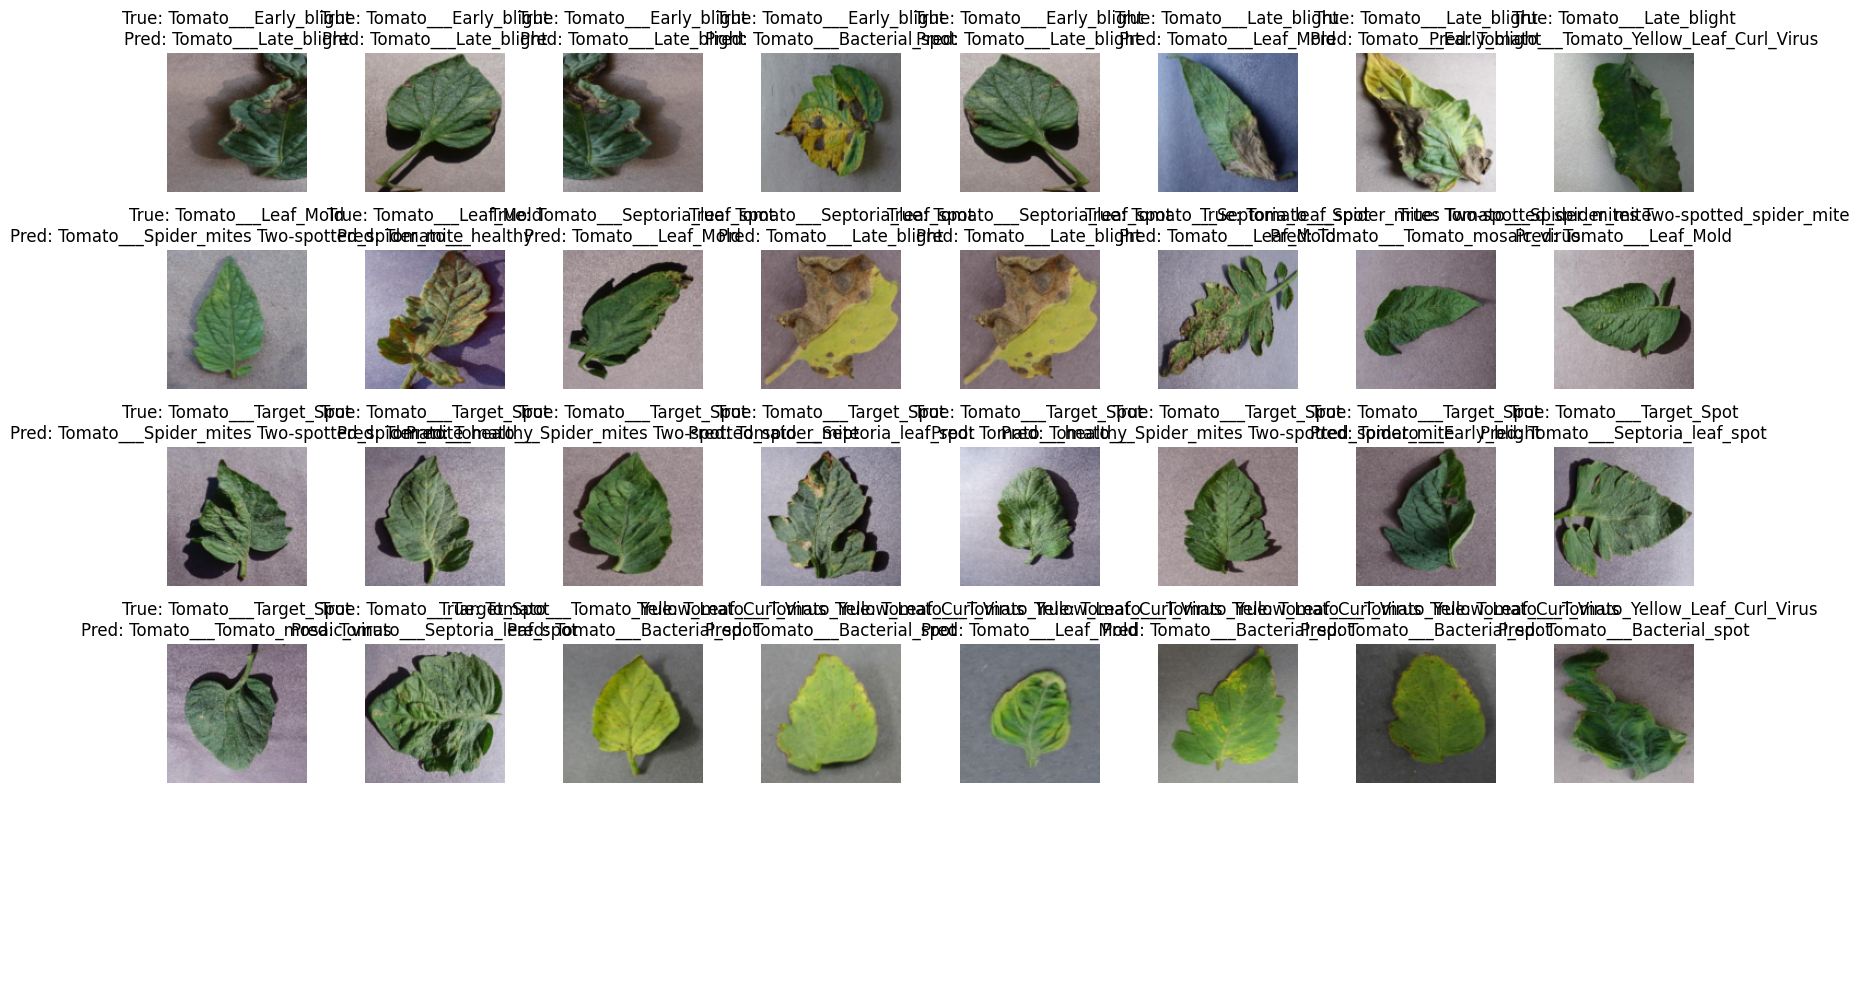

In [ ]:
print(f"Total misclassified samples: {len(misclassified)}")
num_rows = 5   # will change to 6
num_cols = 8  # will change to 6
num_to_show = num_rows * num_cols
num_to_show = min(num_to_show, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()  # flatten for easy iteration

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = img.permute(1, 2, 0)  # CxHxW -> HxWxC
    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}")
    axes[idx].axis('off')

# Turn off any unused subplots
for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

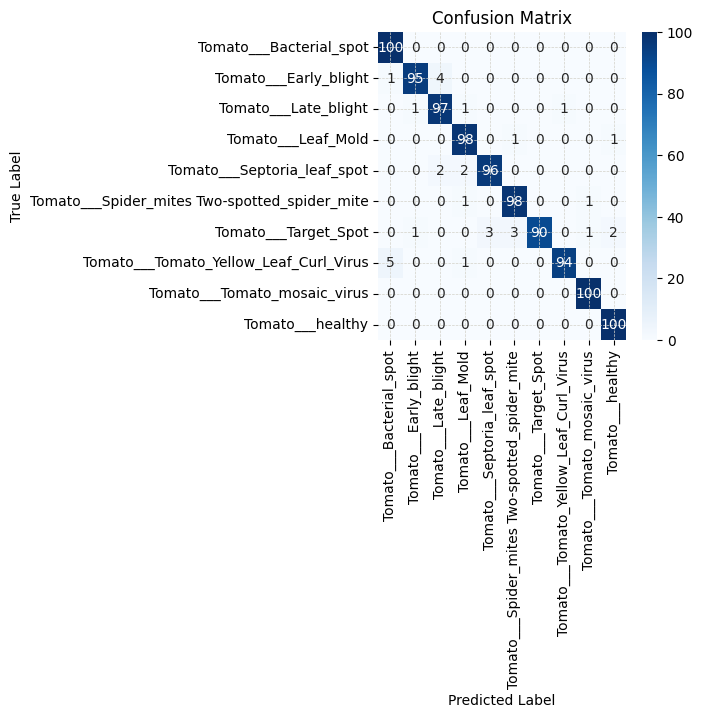

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(4, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=train_data.classes, yticklabels=train_data.classes) # x -> predicted class , y -> actual class
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()